### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# SLC38A4-KO RNA-seq: overview (Fig 3B, 3C, Fig S7, Table S5)

Single analysis notebook for the *overview* panels of the SLC38A4-knockout Huh7.5 RNA-seq experiment. All
panels derive from one limma-voom differential-expression run (KO vs WT).

**Outputs**
- **Fig 3B** — principal-component analysis of the RNA-seq profiles (WT vs KO 1 vs KO 2).
- **Fig 3C** — volcano plot of differential expression (combined KO vs WT), key genes labelled.
- **Fig S7** — cross-clone reproducibility: log2FC concordance (Pearson *r*) and per-clone volcanoes.
- **Table S5** — full differential-expression results (all genes; combined + per clone).

Clone order: **KO 1 = C12, KO 2 = P1.7** (alphabetical; matches the limma pipeline).

**Inputs** (tidy CSVs exported from the limma-voom pipeline; GRCh38/Ensembl 96, filterByExpr min.count = 10):
`Fig3B_voom_logCPM_mincount10.csv` (log2-CPM matrix), `Fig3C_limma_KO_vs_WT_combined_mincount10.csv` (combined DE),
`FigS7_limma_KO1_vs_WT_mincount10.csv` and `FigS7_limma_KO2_vs_WT_mincount10.csv` (per-clone DE).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# ---- house style ----
AXTITLE = 10
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 9, 'axes.linewidth': 1.0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'axes.unicode_minus': False,
})
COLORS = {'WT': '#AAAAAA', 'KO 1': '#D73027', 'KO 2': '#FC8D59'}   # KO 1 = C12, KO 2 = P1.7

# ---- shared thresholds ----
FDR, LFC = 0.05, 1.0
def sig_mask(df):
    return (df['adj.P.Val'] < FDR) & (df['logFC'].abs() > LFC)


## Panel 3B — PCA


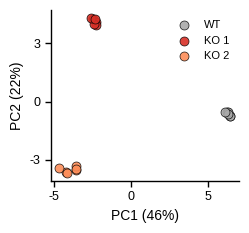

Saved: Fig3B_PCA.pdf | PC1-3 % var: [45.7 22.4  4.2]


In [3]:
expr = pd.read_csv('Fig3B_voom_logCPM_mincount10.csv', index_col=0)
sample_cols = [c for c in expr.columns if c not in ('ensembl_id', 'gene_symbol')]
X = expr[sample_cols].T                      # samples x genes (log2-CPM)

def grp(s):
    return 'WT' if s.startswith('SCWT') else ('KO 1' if s.startswith('C12') else 'KO 2')
groups = np.array([grp(s) for s in sample_cols])

# PCA on all filterByExpr-passing genes (gene-centred) via SVD
Xc = X.values - X.values.mean(0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
pcs = (U * S) / 10
var_expl = (S**2) / (S**2).sum() * 100

fig, ax = plt.subplots(figsize=(2.56, 2.4))
for g in ['WT', 'KO 1', 'KO 2']:
    m = groups == g
    ax.scatter(pcs[m, 0], pcs[m, 1], s=42, color=COLORS[g], edgecolors='black',
               linewidth=0.5, alpha=0.9, label=g)
ax.set_xlabel(f'PC1 ({var_expl[0]:.0f}%)', fontsize=AXTITLE)
ax.set_ylabel(f'PC2 ({var_expl[1]:.0f}%)', fontsize=AXTITLE)
ax.legend(frameon=False, fontsize=8, loc='best')
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
plt.tight_layout()
fig.savefig('Fig3B_PCA.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig3B_PCA.pdf | PC1-3 % var:', var_expl[:3].round(1))


## Panel 3C — Volcano (combined KO vs WT)


DEGs (FDR<0.05, |log2FC|>1.0):  up=575  down=854


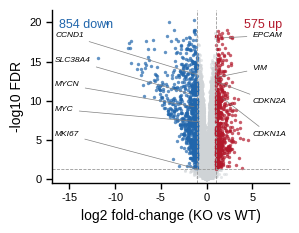

Saved: Fig3C_volcano.pdf


In [4]:
de = pd.read_csv('Fig3C_limma_KO_vs_WT_combined_mincount10.csv', index_col=0).dropna(subset=['gene_symbol'])
de['neglog10fdr'] = -np.log10(de['adj.P.Val'].clip(lower=1e-300))
up   = sig_mask(de) & (de['logFC'] >  0)
down = sig_mask(de) & (de['logFC'] <  0)
print(f'DEGs (FDR<{FDR}, |log2FC|>{LFC}):  up={int(up.sum())}  down={int(down.sum())}')

label_genes = ['EPCAM', 'VIM', 'MYC', 'MYCN', 'CCND1', 'MKI67', 'CDKN1A', 'CDKN2A', 'SLC38A4']

fig, ax = plt.subplots(figsize=(3.06, 2.4))
ax.scatter(de.loc[~(up|down), 'logFC'], de.loc[~(up|down), 'neglog10fdr'],
           s=5, color='#cfd3d6', alpha=0.5, linewidths=0, rasterized=True)
ax.scatter(de.loc[down, 'logFC'], de.loc[down, 'neglog10fdr'], s=6, color='#2166AC', alpha=0.7, linewidths=0)
ax.scatter(de.loc[up,   'logFC'], de.loc[up,   'neglog10fdr'], s=6, color='#B2182B', alpha=0.7, linewidths=0)
ax.axhline(-np.log10(FDR), color='0.6', lw=0.6, ls='--')
ax.axvline(LFC, color='0.6', lw=0.6, ls='--'); ax.axvline(-LFC, color='0.6', lw=0.6, ls='--')
ax.text(.97, .95, f'{int(up.sum()):,} up',   transform=ax.transAxes, ha='right', va='top', color='#B2182B', fontsize=9)
ax.text(.03, .95, f'{int(down.sum()):,} down', transform=ax.transAxes, ha='left',  va='top', color='#2166AC', fontsize=9)

xmin, xmax = de['logFC'].min(), de['logFC'].max()
ymax = de['neglog10fdr'].max()
ax.set_xlim(xmin - 5.0, xmax + 4.5); ax.set_ylim(-0.5, ymax * 1.06)
lab = de[de['gene_symbol'].isin(label_genes)].drop_duplicates('gene_symbol')
for side_df, xanchor, ha in [(lab[lab['logFC'] < 0], xmin - 4.7, 'left'),
                             (lab[lab['logFC'] >= 0], xmax + 0.5, 'left')]:
    ss = side_df.sort_values('neglog10fdr', ascending=False)
    if len(ss) == 0:
        continue
    yslots = np.linspace(ymax * 0.90, ymax * 0.28, len(ss)) if len(ss) > 1 else [ymax * 0.6]
    for ys, (_, r) in zip(yslots, ss.iterrows()):
        ax.annotate(r['gene_symbol'], xy=(r['logFC'], r['neglog10fdr']), xytext=(xanchor, ys),
                    fontsize=6, fontstyle='italic', ha=ha, va='center',
                    arrowprops=dict(arrowstyle='-', color='0.5', lw=0.5))
ax.tick_params(axis='both', labelsize=8)
ax.set_xlabel('log2 fold-change (KO vs WT)', fontsize=AXTITLE)
ax.set_ylabel('-log10 FDR', fontsize=AXTITLE)
plt.tight_layout()
fig.savefig('Fig3C_volcano.pdf', bbox_inches='tight', dpi=500); plt.show()
print('Saved: Fig3C_volcano.pdf')


## Fig S7 — cross-clone reproducibility

Concordance of log2 fold-changes between the two independent knockout clones (**a**), and per-clone volcano
plots (**b**, **c**). High concordance confirms the transcriptomic response is a reproducible consequence of
SLC38A4 loss rather than a clone-specific artefact.


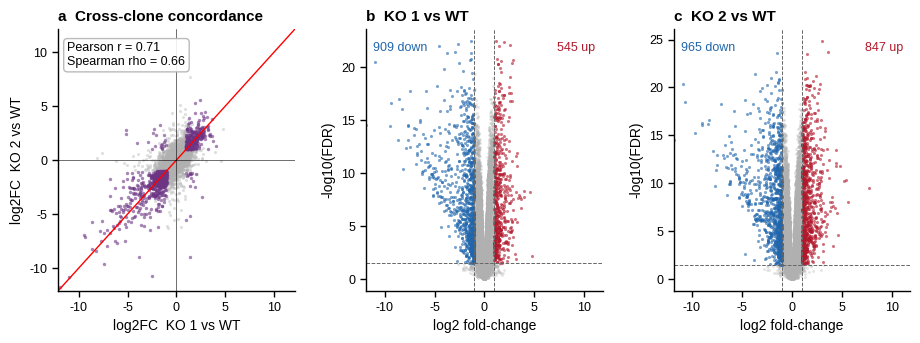

Saved: FigS7_KO_crossclone_reproducibility.pdf | Pearson r=0.713  KO1 sig=1,454  KO2 sig=1,812


In [5]:
c12 = pd.read_csv('FigS7_limma_KO1_vs_WT_mincount10.csv', index_col=0)   # KO 1
p17 = pd.read_csv('FigS7_limma_KO2_vs_WT_mincount10.csv', index_col=0)   # KO 2
UP, DN, NS = '#B2182B', '#2166AC', '#b0b0b0'

fig = plt.figure(figsize=(11, 3.4)); gs = fig.add_gridspec(1, 3, wspace=0.30)

# (a) cross-clone concordance
axA = fig.add_subplot(gs[0, 0])
m = c12[['logFC','adj.P.Val']].join(p17[['logFC','adj.P.Val']], lsuffix='_1', rsuffix='_2', how='inner')
both = (sig_mask(c12).reindex(m.index, fill_value=False) & sig_mask(p17).reindex(m.index, fill_value=False))
r = pearsonr(m['logFC_1'], m['logFC_2'])[0]; rho = spearmanr(m['logFC_1'], m['logFC_2'])[0]
axA.scatter(m.loc[~both,'logFC_1'], m.loc[~both,'logFC_2'], s=5, c=NS, alpha=.4, lw=0, rasterized=True)
axA.scatter(m.loc[both,'logFC_1'],  m.loc[both,'logFC_2'],  s=6, c='#6c3483', alpha=.6, lw=0, rasterized=False)
lim = max(m['logFC_1'].abs().max(), m['logFC_2'].abs().max())*1.02
axA.plot([-lim,lim], [-lim,lim], 'r-', lw=1); axA.axhline(0,c='k',lw=.4); axA.axvline(0,c='k',lw=.4)
axA.set(xlim=(-lim,lim), ylim=(-lim,lim))
axA.set_xlabel('log2FC  KO 1 vs WT', fontsize=AXTITLE); axA.set_ylabel('log2FC  KO 2 vs WT', fontsize=AXTITLE)
axA.set_title('a  Cross-clone concordance', loc='left', fontweight='bold', fontsize=11)
axA.text(.04,.95, f'Pearson r = {r:.2f}\nSpearman rho = {rho:.2f}', transform=axA.transAxes, va='top',
         fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=.9))

def _volc(ax, df, title, letter):
    lp = -np.log10(df['P.Value'].clip(lower=1e-300)); s = sig_mask(df)
    up = s & (df['logFC']>0); dn = s & (df['logFC']<0)
    ax.scatter(df.loc[~s,'logFC'], lp[~s], s=4, c=NS, alpha=.35, lw=0, rasterized=True)
    ax.scatter(df.loc[dn,'logFC'], lp[dn], s=5, c=DN, alpha=.6, lw=0, rasterized=False)
    ax.scatter(df.loc[up,'logFC'], lp[up], s=5, c=UP, alpha=.6, lw=0, rasterized=False)
    ax.axvline(LFC, ls='--', c='0.4', lw=.7); ax.axvline(-LFC, ls='--', c='0.4', lw=.7)
    ax.axhline(-np.log10(df.loc[df['adj.P.Val']<FDR,'P.Value'].max()), ls='--', c='0.4', lw=.7)
    xl = max(df['logFC'].abs().max(), 1.5)
    ax.set(xlim=(-xl,xl))
    ax.set_xlabel('log2 fold-change', fontsize=AXTITLE); ax.set_ylabel('-log10(FDR)', fontsize=AXTITLE)
    ax.set_title(f'{letter}  {title}', loc='left', fontweight='bold', fontsize=11)
    ax.text(.97,.95, f'{int(up.sum()):,} up',   transform=ax.transAxes, ha='right', va='top', color=UP, fontsize=9)
    ax.text(.03,.95, f'{int(dn.sum()):,} down', transform=ax.transAxes, ha='left',  va='top', color=DN, fontsize=9)

_volc(fig.add_subplot(gs[0,1]), c12, 'KO 1 vs WT', 'b')
_volc(fig.add_subplot(gs[0,2]), p17, 'KO 2 vs WT', 'c')
fig.savefig('FigS7_KO_crossclone_reproducibility.pdf', bbox_inches='tight', dpi=500); plt.show()
print(f'Saved: FigS7_KO_crossclone_reproducibility.pdf | Pearson r={r:.3f}  '
      f'KO1 sig={int(sig_mask(c12).sum()):,}  KO2 sig={int(sig_mask(p17).sum()):,}')


## Table S5 — full differential-expression results

All genes reported (not filtered); `significant`/`direction` columns flag the FDR<0.05 & |log2FC|>1 threshold.
Three sheets: combined KO vs WT, and each clone vs WT. Matches the ranked list used for pre-ranked GSEA.

In [6]:
ST_PATH = 'Table_S5_SLC38A4_KO_DE.xlsx'
_cols = ['gene_symbol','ensembl_id','logFC','AveExpr','t','P.Value','adj.P.Val','B']
def _tidy(df):
    d = df[_cols].copy()
    d['direction']   = np.where((d['adj.P.Val']<FDR)&(d['logFC']> LFC), 'up',
                       np.where((d['adj.P.Val']<FDR)&(d['logFC']<-LFC), 'down', 'ns'))
    d['significant'] = d['direction'] != 'ns'
    return d.sort_values('adj.P.Val')

_sheets = {'KO_vs_WT_combined': de, 'KO1_vs_WT': c12, 'KO2_vs_WT': p17}
_readme = pd.DataFrame({'Table S5. SLC38A4 knockout differential expression (combined KO1+KO2 vs WT, and each clone vs WT)': [
    f'limma-voom, Huh7.5 SLC38A4 KO vs WT (RSEM; filterByExpr min.count=10; {len(de):,} genes tested).',
    f'Significance flag: FDR (adj.P.Val) < {FDR:g} AND |log2 fold-change| > {LFC:g}.',
    'Sheet KO_vs_WT_combined: combined KO (KO1+KO2) vs WT.  KO1_vs_WT / KO2_vs_WT: each clone vs WT.',
    'All genes reported (not filtered); significant/direction columns flag the threshold.',
]})
with pd.ExcelWriter(ST_PATH, engine='openpyxl') as xw:
    _readme.to_excel(xw, sheet_name='README', index=False)
    for name, df in _sheets.items():
        _tidy(df).to_excel(xw, sheet_name=name, index=True, index_label='gene_id')
for name, df in _sheets.items():
    t = _tidy(df); print(f'  {name}: {int(t["significant"].sum()):,} significant / {len(t):,} genes')
print(f'Saved: {ST_PATH}')


  KO_vs_WT_combined: 1,429 significant / 14,113 genes
  KO1_vs_WT: 1,454 significant / 14,113 genes
  KO2_vs_WT: 1,812 significant / 14,113 genes
Saved: Table_S5_SLC38A4_KO_DE.xlsx
